**ANOMALY DETECTION PAC-MD-ENCODERS**

In [1]:
import digitalhub as dh
import zipfile
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


**SETUP PARAMETERS**

In [2]:
job_name = "attn_0per_enc"
dataset_standard = "Standard"
dataset_anomalies = "Floods_Anomalies_v3_crop_norm"
moco_version = "net_v3"

parameters = {
    "job_name": job_name,                          
    "dataset_standard": dataset_standard,
    "dataset_anomalies": dataset_anomalies,         
    "moco_version": moco_version, 
    "old_vectors": "", 
    "min_flood_area": 0.0,
    "moco_attn": False,                 
    "weights_sar":  "autoencoder_2D_SAR_weights_convLstm_v1",
    "weights_opt":  "autoencoder_2D_OPT_weights_convLstm_v1", 
    "pca_components": None, 
    "pool_grid": 4,

    "patch_size": 256,
    "n_images1": 4, "n_channels1": 2,       # sar
    "n_images2": 4, "n_channels2": 10,      # ottico       
    "standardize": True,                    
    "batch_size": 16,
    "workers": 0,
}

volumes = [
    {
        "volume_type": "ephemeral",
        "name": "volume-spazio-dati",
        "mount_path": "/data",
        "spec": {"size": "200Gi"}
    }
]

**BUILD ENVIRONMENT**

In [5]:
ocsvm_func = project.new_function(
    name=f'md_enc',
    kind="python",
    python_version="PYTHON3_10",
    code_src="../../src/",
    handler="anomaly:ad_md_encoders",
    image="harbor.atlas.fbk.eu/rsde/rsde-platform-floods-floodsimagev3:9b7e2",
)

**TRAINING**

In [6]:
resources = {"cpu": "4", "mem": "20Gi"}

run_ad = ocsvm_func.run(
    action="job",
    parameters=parameters,
    volumes=volumes,
    resources = resources,
    profile="1xv100-shared",
    local_execution=False,
    wait=True
)

print(f"Run anomaly detection ocsvm: {run_ad.id}")

2026-10-26 15:52:35,431 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run de138a53e5214478b79e49966cd8b351 to finish...
2026-10-26 15:52:40,439 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run de138a53e5214478b79e49966cd8b351 to finish...
2026-10-26 15:52:45,448 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run de138a53e5214478b79e49966cd8b351 to finish...
2026-10-26 15:52:50,457 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run de138a53e5214478b79e49966cd8b351 to finish...
2026-10-26 15:52:55,466 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run de138a53e5214478b79e49966cd8b351 to finish...
2026-10-26 15:53:00,476 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run de138a53e5214478b79e49966cd8b351 to finish...
2026-10-26 15:53:05,487 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run de138a53e5214478b79e49966cd8b351 to finish...
2026-10-26 15

Run anomaly detection ocsvm: de138a53e5214478b79e49966cd8b351


In [7]:
RESULTS_DIR = "/tmp/anomaly_results_pca"

zip_path = project.get_artifact(f"anomaly_results_mdenc_{job_name}").download("/tmp/anomaly_results_pca.zip", overwrite=True)
with zipfile.ZipFile(zip_path) as z:
    z.extractall(RESULTS_DIR)
with open(f"{RESULTS_DIR}/anomaly_results.json") as f:
    results = json.load(f)

df = pd.read_csv(f"{RESULTS_DIR}/scores.csv")                    
score_normal = df[df.label == 0]['score']
score_anom = df[df.label == 1]['score']

print(f"n_fit: {results['n_fit']} | n_thr: {results['n_thr']} | n_normali: {results['n_normali']} | n_anomale: {results['n_anomale']}", "\n")
print(f"n_componenti = {results['n_componenti']:.3f} | standardize={results['standardize']}")
print(f"min_flood_area = {results['min_flood_area']:.3f}")
print(f"score normali: {score_normal.mean():.4f} ± {score_normal.std():.4f}")
print(f"score anomale: {score_anom.mean():.4f} ± {score_anom.std():.4f}", "\n")
print(f"AUROC (score basso = anomalia): {results['auroc']:.3f}")

df_rules = pd.DataFrame(results['rules']).T
df_rules

n_fit: 2072 | n_thr: 500 | n_normali: 2402 | n_anomale: 2402 

n_componenti = 512.000 | standardize=True
min_flood_area = 0.000
score normali: -695.5357 ± 289.3744
score anomale: -1236.8063 ± 483.8181 

AUROC (score basso = anomalia): 0.854


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-1223.982356,1050.0,132.0,1352.0,2270.0,0.054954,0.562864,0.437136,0.888325,0.585938
FA 10%,-1066.656096,1392.0,221.0,1010.0,2181.0,0.092007,0.420483,0.579517,0.862988,0.693400
FA 15%,-969.877665,1584.0,344.0,818.0,2058.0,0.143214,0.340550,0.659450,0.821577,0.731640
FA 20%,-880.831383,1762.0,496.0,640.0,1906.0,0.206495,0.266445,0.733555,0.780337,0.756223
FA 25%,-839.969455,1860.0,594.0,542.0,1808.0,0.247294,0.225645,0.774355,0.757946,0.766063
FA 30%,-795.796381,1945.0,701.0,457.0,1701.0,0.291840,0.190258,0.809742,0.735072,0.770602


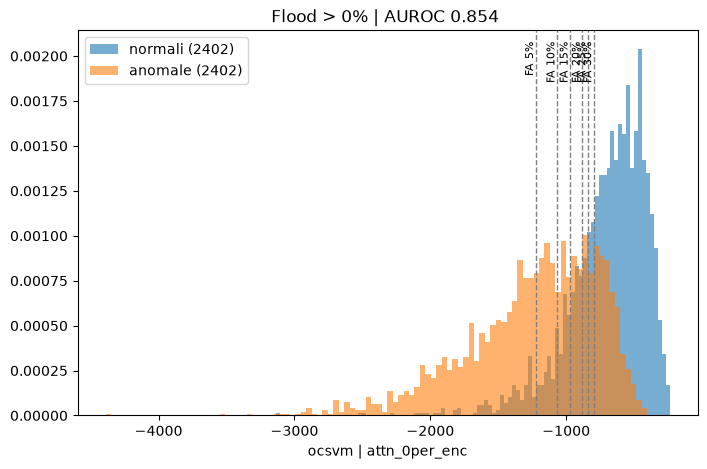

In [8]:
df = pd.read_csv(f"{RESULTS_DIR}/scores.csv")
score_normal = df[df.label == 0]['score']
score_anom = df[df.label == 1]['score']

lo, hi = np.quantile(df.score, [0.005, 0.995])                   
bins = np.linspace(lo, hi, 100)

plt.figure(figsize=(8, 5))
plt.hist(score_normal, bins=100, alpha=0.6, density=True, label=f"normali ({len(score_normal)})")
plt.hist(score_anom, bins=100, alpha=0.6, density=True, label=f"anomale ({len(score_anom)})")
for nome, r in results['rules'].items():                         
    if lo <= r["soglia"] <= hi:
        plt.axvline(x=r["soglia"], color='gray', linestyle='--', linewidth=1)
        plt.text(r["soglia"], plt.ylim()[1] * 0.97, nome.split("(")[-1].rstrip(")"), rotation=90, va="top", ha="right", fontsize=8)   
plt.xlabel(f"ocsvm | {job_name}")
plt.legend()
plt.title(f"Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f} ")
plt.show()

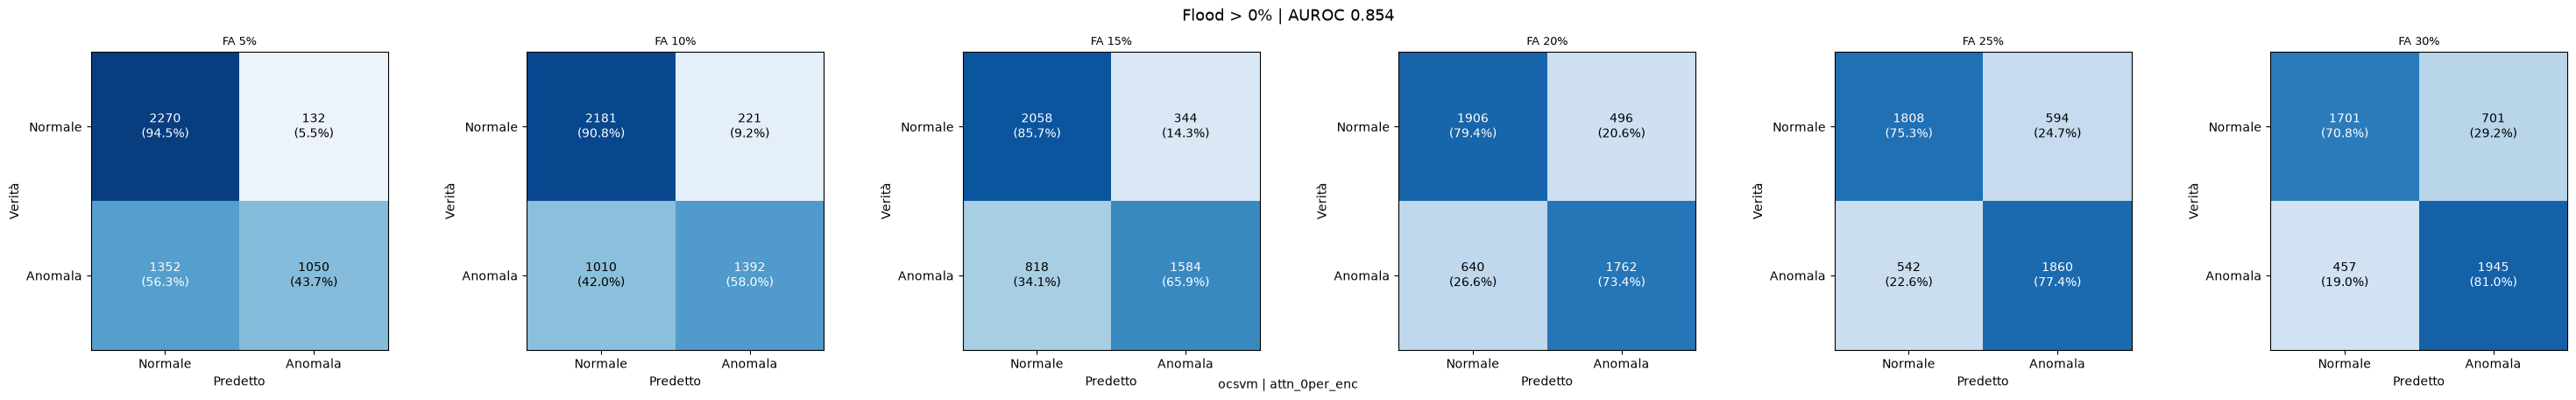

In [9]:
rules = results['rules']
fig, axes = plt.subplots(1, len(rules), figsize=(5 * len(rules), 4.5), squeeze=False)

for ax, (nome, r) in zip(axes[0], rules.items()):
    mat = np.array([[r["TN"], r["FP"]],
                     [r["FN"], r["TP"]]])
    mat_pct = mat / mat.sum(axis=1, keepdims=True) * 100

    im = ax.imshow(mat_pct, cmap="Blues", vmin=0, vmax=100)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Normale", "Anomala"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Normale", "Anomala"])
    ax.set_xlabel("Predetto"); ax.set_ylabel("Verità")
    ax.set_title(nome, fontsize=9)

    for i in range(2):
        for j in range(2):
            color = "white" if mat_pct[i, j] > 55 else "black"
            ax.text(j, i, f"{int(mat[i, j])}\n({mat_pct[i, j]:.1f}%)",
                    ha="center", va="center", color=color, fontsize=10)

fig.suptitle(f"Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}", fontsize=13)
fig.text(0.5, 0.01, f"ocsvm | {job_name}", ha="center", va="bottom", fontsize=10)              

plt.tight_layout()
plt.show()